# Evaluation of Computer Vision Models
**Groupe 1** · Détection d'objets · Segmentation sémantique · Segmentation d'instances

Dans ce notebook on fait trois expériences avec des **modèles déjà entraînés** (on n'entraîne rien) :

| Partie | Modèle | Ce qu'on mesure |
|---|---|---|
| 1. Object Detection | Faster R-CNN | IoU, Precision, Recall, mAP |
| 2. Semantic Segmentation | DeepLabV3 | Pixel Accuracy, IoU / mIoU, Dice |
| 3. Instance Segmentation | Mask R-CNN | IoU et Dice des masques, Mask mAP |

**Idée centrale :** on compare la **prédiction** du modèle à la **Ground Truth** (la bonne réponse, annotée par des humains dans le dataset COCO).

> Avant de lancer : menu **Exécution > Modifier le type d'exécution > GPU (T4)**, puis **Exécution > Tout exécuter**. Compter 5 à 10 minutes.

## 0. Préparation

In [ ]:
!pip install -q pycocotools torchmetrics

In [ ]:
import os, random, requests
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
from torchvision.transforms import functional as TF

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(0); np.random.seed(0); torch.manual_seed(0)
print('Appareil utilisé :', device)

Appareil utilisé : cuda


### Les données et la Ground Truth
On utilise **COCO** (val2017). Il contient pour chaque image les boîtes et les masques dessinés par des humains : c'est notre Ground Truth.
On télécharge seulement le fichier d'annotations de validation, puis un petit nombre d'images.

In [ ]:
if not os.path.exists('instances_val2017.json'):
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
    !unzip -q -j annotations_trainval2017.zip annotations/instances_val2017.json
    !rm -f annotations_trainval2017.zip

coco = COCO('instances_val2017.json')
cats = {c['id']: c['name'] for c in coco.loadCats(coco.getCatIds())}   # id COCO -> nom de classe
print(len(cats), 'classes dans COCO')

loading annotations into memory...
Done (t=2.11s)
creating index...
index created!
80 classes dans COCO


In [ ]:
# Les classes que DeepLabV3 sait segmenter (les 20 classes de Pascal VOC + le fond)
VOC_NAMES = ['background','aeroplane','bicycle','bird','boat','bottle','bus','car','cat','chair','cow',
             'diningtable','dog','horse','motorbike','person','pottedplant','sheep','sofa','train','tvmonitor']
VOC_TO_COCO = {'aeroplane':'airplane','diningtable':'dining table','motorbike':'motorcycle',
               'pottedplant':'potted plant','sofa':'couch','tvmonitor':'tv'}
coco_name_to_voc = {VOC_TO_COCO.get(n, n): i for i, n in enumerate(VOC_NAMES) if i > 0}

N_IMAGES = 20   # on peut augmenter si on a le temps

def annotations(img_id):
    # annotations sans les zones 'foule' (iscrowd)
    return coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=0))

ids = coco.getImgIds(); random.shuffle(ids)
selected = []
for i in ids:
    anns = annotations(i)
    names = {cats[a['category_id']] for a in anns}
    if 2 <= len(anns) <= 8 and names & set(coco_name_to_voc):
        selected.append(i)
    if len(selected) == N_IMAGES: break

os.makedirs('imgs', exist_ok=True)
def load_image(i):
    info = coco.loadImgs(i)[0]; path = 'imgs/' + info['file_name']
    if not os.path.exists(path):
        open(path, 'wb').write(requests.get(info['coco_url'], timeout=30).content)
    return Image.open(path).convert('RGB')

images = {i: load_image(i) for i in selected}
print(len(images), 'images prêtes')

20 images prêtes


In [ ]:
def gt_boxes_labels(i):
    # Ground Truth de détection : boîtes [x1,y1,x2,y2] et classes
    anns = annotations(i)
    boxes = np.array([[a['bbox'][0], a['bbox'][1], a['bbox'][0]+a['bbox'][2], a['bbox'][1]+a['bbox'][3]] for a in anns],
                     dtype=np.float32).reshape(-1, 4)
    labels = np.array([a['category_id'] for a in anns], dtype=np.int64)
    return boxes, labels

def draw_boxes(ax, img, boxes, labels, scores=None, color='lime', title=''):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
    for k, b in enumerate(boxes):
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, color=color, lw=2))
        txt = cats.get(int(labels[k]), '?') + (f' {scores[k]:.2f}' if scores is not None else '')
        ax.text(b[0], max(b[1]-3, 8), txt, color='white', fontsize=8, backgroundcolor=color)

## Partie 1 · Object Detection (Faster R-CNN)

Le modèle dessine des **rectangles (bounding boxes)** autour des objets, avec une **classe** et un **score de confiance**.

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
det_model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT).to(device).eval()

@torch.no_grad()
def predict_det(img):
    out = det_model([TF.to_tensor(img).to(device)])[0]
    return {k: v.cpu() for k, v in out.items()}

det_preds = {i: predict_det(images[i]) for i in selected}
print('Détection terminée')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 174MB/s]


Détection terminée


### Ground Truth (vert) contre Prédiction (rouge)

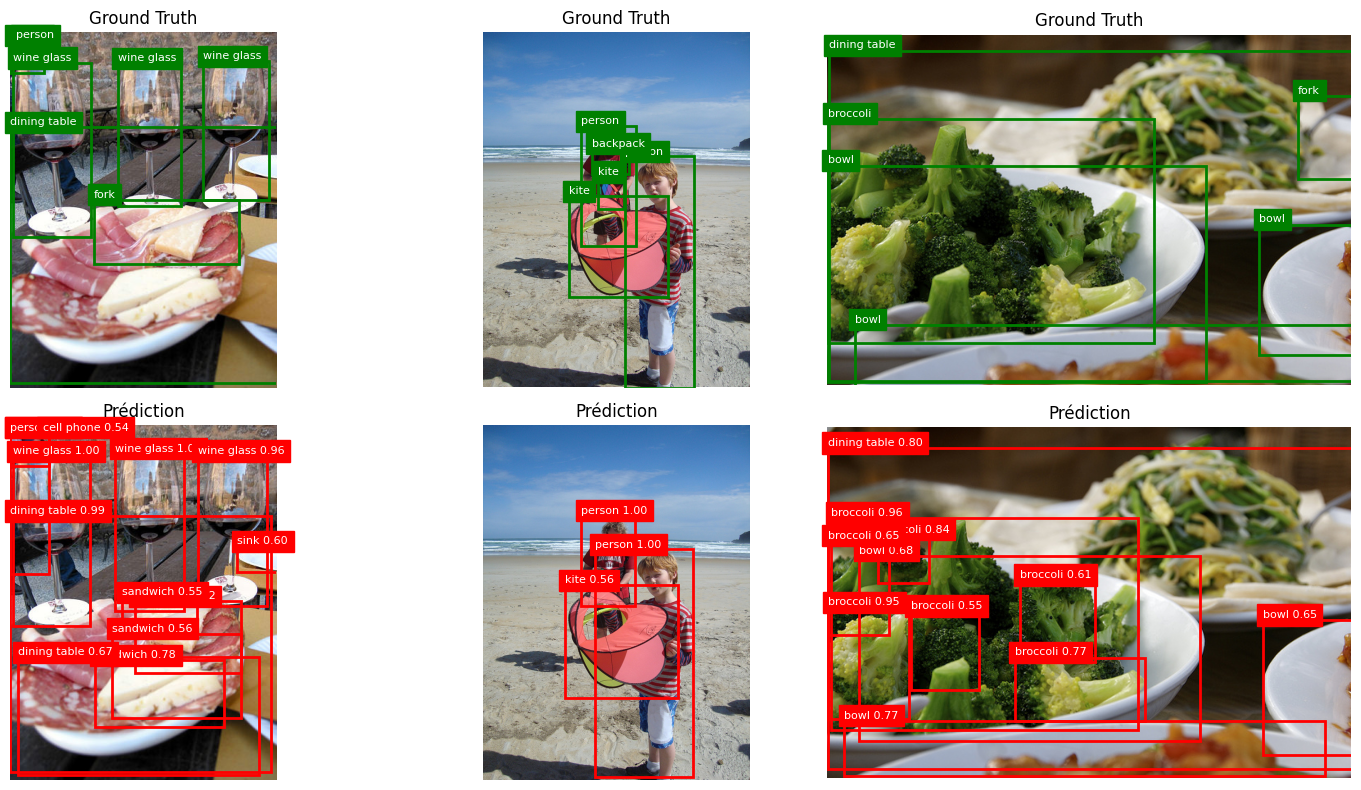

In [ ]:
SCORE_THR = 0.5   # on garde les prédictions sûres à plus de 50 %
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, i in enumerate(selected[:3]):
    gb, gl = gt_boxes_labels(i); p = det_preds[i]; keep = p['scores'] >= SCORE_THR
    draw_boxes(axes[0, row], images[i], gb, gl, color='green', title='Ground Truth')
    draw_boxes(axes[1, row], images[i], p['boxes'][keep].numpy(), p['labels'][keep].numpy(),
               p['scores'][keep].numpy(), color='red', title='Prédiction')
plt.tight_layout(); plt.show()

### Métrique 1 : l'IoU (Intersection over Union)
**IoU = zone commune ÷ zone totale** entre la boîte prédite et la boîte réelle. 1 = parfait, 0 = rien en commun.

In [ ]:
def iou_box(a, b):
    # a et b = [x1, y1, x2, y2]
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

# Exemple simple : deux rectangles qui se chevauchent
print('IoU exemple =', round(iou_box([10, 10, 50, 50], [20, 20, 60, 60]), 3))

# Sur une vraie image : IoU entre chaque objet réel et la meilleure prédiction
i = selected[0]; gb, gl = gt_boxes_labels(i); p = det_preds[i]
for j in range(len(gb)):
    best = max([iou_box(p['boxes'][k].numpy(), gb[j]) for k in range(len(p['boxes']))] or [0])
    print(f'objet réel {cats[int(gl[j])]:<12} meilleure IoU = {best:.2f}')

IoU exemple = 0.391
objet réel dining table meilleure IoU = 0.95
objet réel person       meilleure IoU = 0.82
objet réel person       meilleure IoU = 0.62
objet réel wine glass   meilleure IoU = 0.83
objet réel wine glass   meilleure IoU = 0.96
objet réel wine glass   meilleure IoU = 0.81
objet réel fork         meilleure IoU = 0.72


### Métriques 2 et 3 : Precision et Recall
On dit qu'une détection est correcte (**TP**) si la classe est bonne **et** IoU ≥ 0,5.
- **FP** : détection à tort (fausse alerte). **FN** : objet réel oublié.
- **Precision = TP ÷ (TP + FP)** : parmi ce que le modèle détecte, combien est juste ?
- **Recall = TP ÷ (TP + FN)** : parmi les objets réels, combien le modèle en trouve ?

In [ ]:
def match_detections(pred_boxes, pred_labels, pred_scores, gt_boxes, gt_labels, iou_thr=0.5):
    used, tp, fp = set(), 0, 0
    for k in np.argsort(-pred_scores):               # on commence par les plus sûres
        best, best_iou = -1, 0.0
        for j in range(len(gt_boxes)):
            if j in used or gt_labels[j] != pred_labels[k]: continue
            v = iou_box(pred_boxes[k], gt_boxes[j])
            if v > best_iou: best_iou, best = v, j
        if best >= 0 and best_iou >= iou_thr: used.add(best); tp += 1
        else: fp += 1
    return tp, fp, len(gt_boxes) - len(used)

TP = FP = FN = 0
for i in selected:
    gb, gl = gt_boxes_labels(i); p = det_preds[i]; keep = (p['scores'] >= SCORE_THR).numpy()
    tp, fp, fn = match_detections(p['boxes'].numpy()[keep], p['labels'].numpy()[keep], p['scores'].numpy()[keep], gb, gl)
    TP += tp; FP += fp; FN += fn

precision = TP / max(TP + FP, 1); recall = TP / max(TP + FN, 1)
print(f'TP={TP}  FP={FP}  FN={FN}')
print(f'Precision = {precision:.2%}   Recall = {recall:.2%}')

TP=54  FP=57  FN=24
Precision = 48.65%   Recall = 69.23%


### Métrique 4 : mAP (mean Average Precision)
Résume la qualité globale du détecteur sur **toutes les classes** et tous les scores de confiance.
- **mAP@50** : seuil IoU de 0,5 (plus facile). **mAP@50:95** : moyenne sur plusieurs seuils de 0,5 à 0,95 (plus strict, style COCO).

In [ ]:
from torchmetrics.detection import MeanAveragePrecision

metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox')
preds = [dict(boxes=det_preds[i]['boxes'], scores=det_preds[i]['scores'], labels=det_preds[i]['labels']) for i in selected]
targets = [dict(boxes=torch.tensor(gt_boxes_labels(i)[0]), labels=torch.tensor(gt_boxes_labels(i)[1])) for i in selected]
metric.update(preds, targets)
res = metric.compute()
map50, map5095 = res['map_50'].item(), res['map'].item()
print(f'mAP@50    = {map50:.3f}')
print(f'mAP@50:95 = {map5095:.3f}   (toujours plus bas, car plus strict)')

mAP@50    = 0.636
mAP@50:95 = 0.435   (toujours plus bas, car plus strict)


## Partie 2 · Semantic Segmentation (DeepLabV3)

Le modèle donne **une classe à chaque pixel** (route, personne, chat...). Il ne distingue pas deux objets de la même classe.

Pour la Ground Truth, on fabrique un masque de classes à partir des annotations COCO (les classes que DeepLabV3 ne connaît pas comptent comme *fond*).

In [ ]:
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
w2 = DeepLabV3_ResNet50_Weights.DEFAULT
seg_model = deeplabv3_resnet50(weights=w2).to(device).eval()
prep = w2.transforms()

@torch.no_grad()
def predict_sem(img):
    out = seg_model(prep(img).unsqueeze(0).to(device))['out']
    out = torch.nn.functional.interpolate(out, size=(img.height, img.width), mode='bilinear', align_corners=False)
    return out.argmax(1)[0].cpu().numpy()          # une classe par pixel

def gt_semantic(i):
    info = coco.loadImgs(i)[0]; mask = np.zeros((info['height'], info['width']), dtype=np.int64)
    for a in sorted(annotations(i), key=lambda a: -a['area']):      # les petits objets par-dessus
        name = cats[a['category_id']]
        if name in coco_name_to_voc: mask[coco.annToMask(a) > 0] = coco_name_to_voc[name]
    return mask

sem_preds = {i: predict_sem(images[i]) for i in selected}
sem_gt = {i: gt_semantic(i) for i in selected}
print('Segmentation sémantique terminée')

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 174MB/s]


Segmentation sémantique terminée


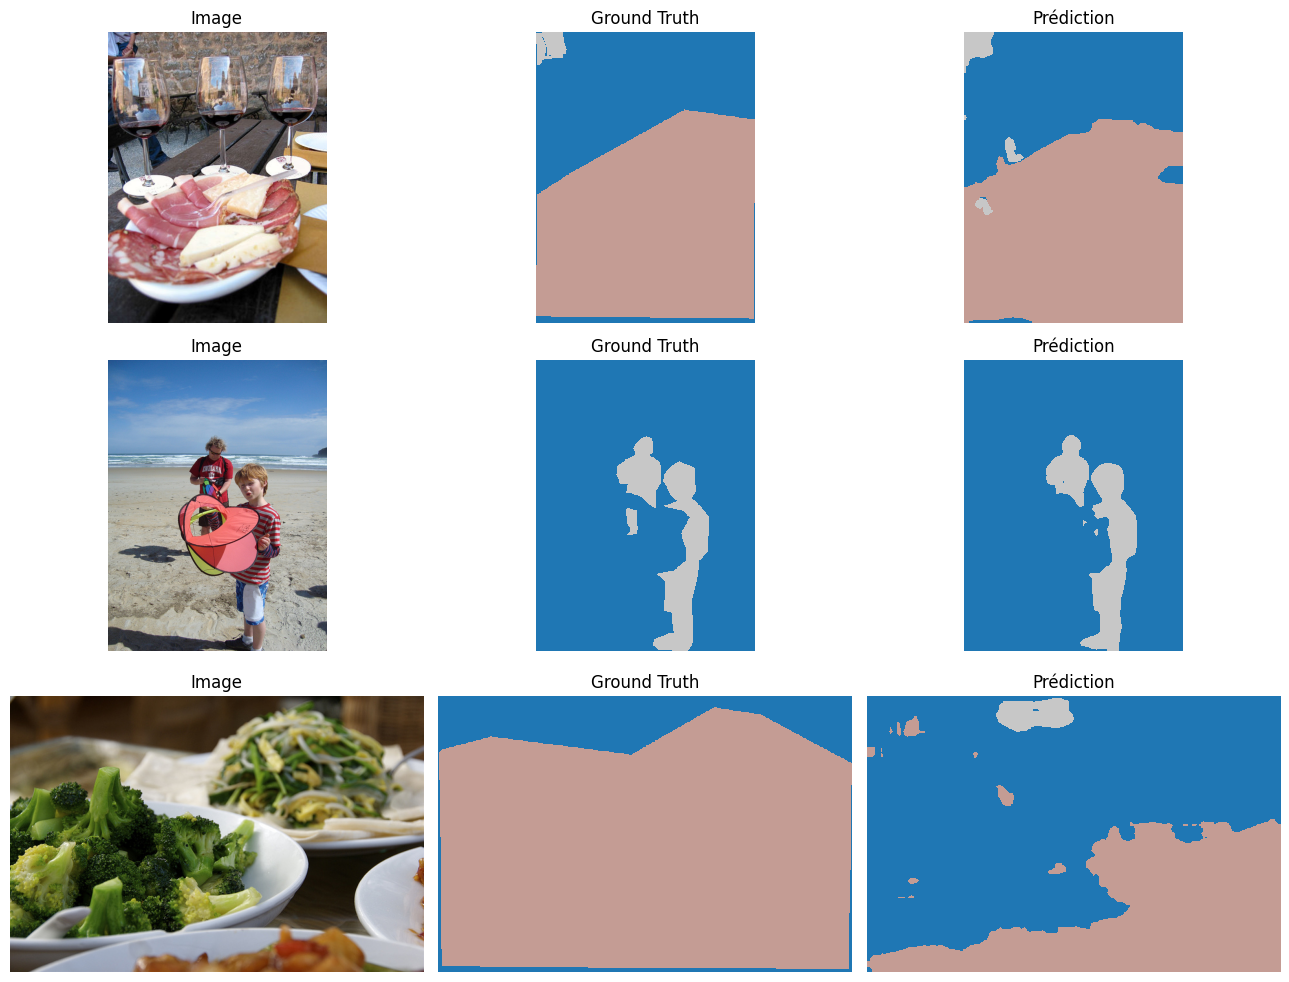

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for row, i in enumerate(selected[:3]):
    axes[row, 0].imshow(images[i]); axes[row, 0].set_title('Image')
    axes[row, 1].imshow(sem_gt[i], cmap='tab20', vmin=0, vmax=20, interpolation='nearest'); axes[row, 1].set_title('Ground Truth')
    axes[row, 2].imshow(sem_preds[i], cmap='tab20', vmin=0, vmax=20, interpolation='nearest'); axes[row, 2].set_title('Prédiction')
    for a in axes[row]: a.axis('off')
plt.tight_layout(); plt.show()

### Les métriques de segmentation
On compte, pour chaque classe, les pixels bien et mal classés (matrice de confusion), puis :
- **Pixel Accuracy** = pixels corrects ÷ pixels totaux.
- **IoU** d'une classe = chevauchement des pixels prédits et réels. **mIoU** = moyenne sur les classes.
- **Dice** = 2 × zone commune ÷ (taille prédite + taille réelle).

In [ ]:
def confusion(gt, pred, n=21):
    return np.bincount(n * gt.ravel() + pred.ravel(), minlength=n * n).reshape(n, n)

cm = sum(confusion(sem_gt[i], sem_preds[i]) for i in selected)
diag = np.diag(cm); gt_sum, pr_sum = cm.sum(1), cm.sum(0)
union = gt_sum + pr_sum - diag

pixel_acc = diag.sum() / cm.sum()
iou  = np.where(union > 0, diag / np.maximum(union, 1), np.nan)
dice = np.where((gt_sum + pr_sum) > 0, 2 * diag / np.maximum(gt_sum + pr_sum, 1), np.nan)
miou, mdice = np.nanmean(iou), np.nanmean(dice)

table = pd.DataFrame({'classe': VOC_NAMES, 'IoU': iou.round(3), 'Dice': dice.round(3), 'pixels réels': gt_sum}).dropna()
display(table.sort_values('pixels réels', ascending=False).reset_index(drop=True))
print(f'Pixel Accuracy = {pixel_acc:.2%}')
print(f'mIoU           = {miou:.3f}')
print(f'mDice          = {mdice:.3f}')
print(f'Part du fond dans les pixels réels : {gt_sum[0] / cm.sum():.1%}')

,classe,IoU,Dice,pixels réels
0,background,0.888,0.940,4140619
1,person,0.805,0.892,502910
2,diningtable,0.497,0.664,364487
3,sofa,0.910,0.953,282097
4,cat,0.898,0.946,138767
5,chair,0.831,0.907,99907
6,aeroplane,0.870,0.930,29513
7,cow,0.613,0.760,12833
8,boat,0.088,0.161,7999
9,bicycle,0.290,0.450,3110


Pixel Accuracy = 91.00%
mIoU           = 0.504
mDice          = 0.569
Part du fond dans les pixels réels : 74.1%


> **À remarquer (piège) :** la Pixel Accuracy est souvent très élevée parce que le **fond** occupe beaucoup de pixels et est facile à reconnaître. Le mIoU est plus bas car il traite chaque classe de la même façon, même les petites. C'est pour ça qu'on ne se fie pas à la Pixel Accuracy seule.

## Partie 3 · Instance Segmentation (Mask R-CNN)

Le modèle donne **un masque par objet** : voiture 1, voiture 2... Chaque objet a aussi sa classe et son score. On évalue avec l'IoU et le Dice des masques, puis la **Mask mAP**.

In [ ]:
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
inst_model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).to(device).eval()

@torch.no_grad()
def predict_inst(img):
    out = inst_model([TF.to_tensor(img).to(device)])[0]
    out = {k: v.cpu() for k, v in out.items()}
    out['masks'] = out['masks'][:, 0] > 0.5            # (nb_objets, H, W) en vrai/faux
    return out

inst_preds = {i: predict_inst(images[i]) for i in selected}

def gt_instances(i):
    anns = annotations(i)
    masks = torch.tensor(np.stack([coco.annToMask(a) for a in anns]).astype(bool))
    return masks, torch.tensor([a['category_id'] for a in anns], dtype=torch.int64)
print('Segmentation d\'instances terminée')

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 166MB/s]


Segmentation d'instances terminée


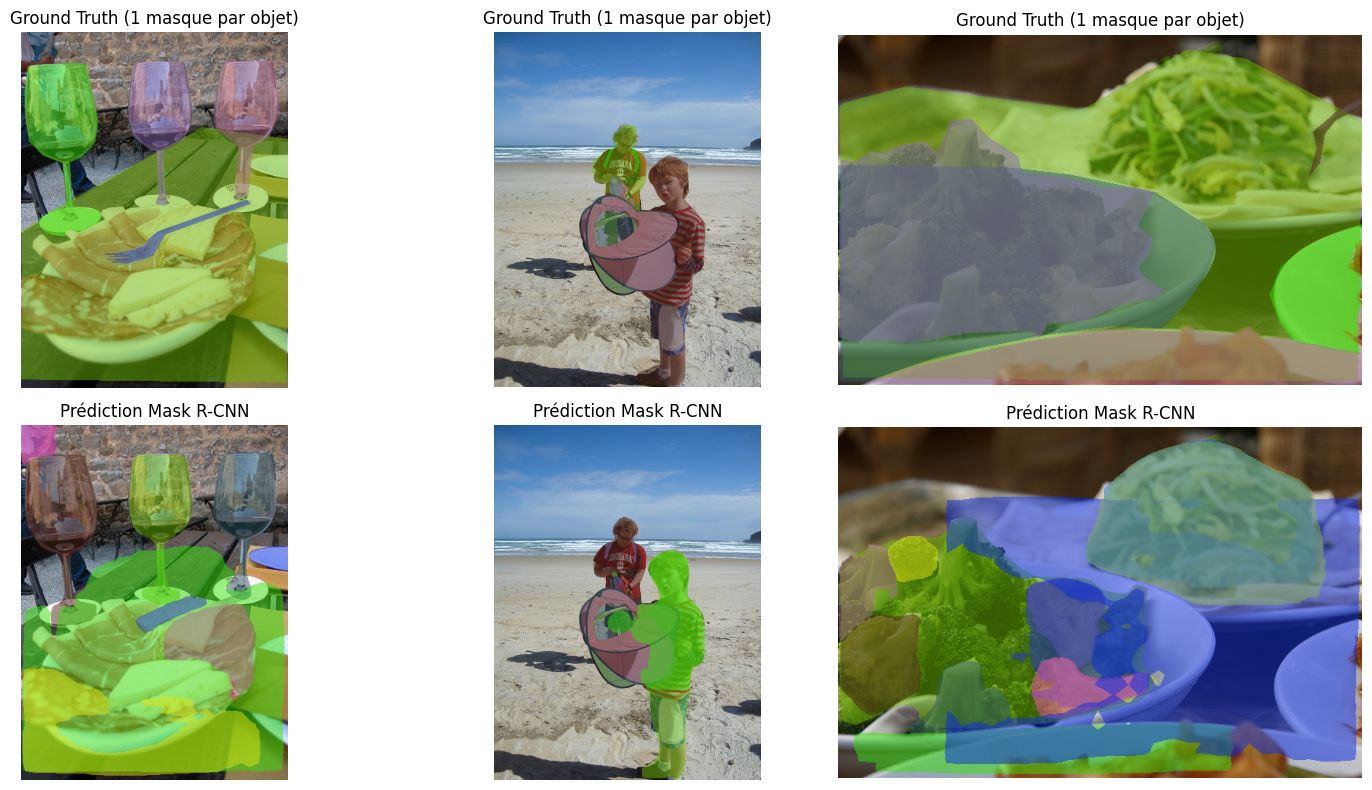

In [ ]:
def overlay(ax, img, masks, title=''):
    canvas = np.array(img).astype(float) / 255
    rng = np.random.RandomState(1)
    for m in masks:                                     # une couleur différente par objet
        color = rng.rand(3)
        canvas[m.numpy()] = 0.5 * canvas[m.numpy()] + 0.5 * color
    ax.imshow(canvas); ax.set_title(title); ax.axis('off')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, i in enumerate(selected[:3]):
    gm, _ = gt_instances(i); p = inst_preds[i]; keep = p['scores'] >= 0.5
    overlay(axes[0, col], images[i], gm, 'Ground Truth (1 masque par objet)')
    overlay(axes[1, col], images[i], p['masks'][keep], 'Prédiction Mask R-CNN')
plt.tight_layout(); plt.show()

### IoU et Dice sur les masques (un objet à la fois)

In [ ]:
def mask_iou(a, b):
    inter = (a & b).sum().item(); union = (a | b).sum().item()
    return inter / union if union else 0.0

def mask_dice(a, b):
    inter = (a & b).sum().item(); total = a.sum().item() + b.sum().item()
    return 2 * inter / total if total else 0.0

i = selected[0]; gm, gl = gt_instances(i); p = inst_preds[i]; keep = p['scores'] >= 0.5
rows = []
for j in range(len(gm)):
    best_iou, best_dice = 0.0, 0.0
    for k in torch.where(keep)[0]:
        if p['labels'][k] == gl[j]:
            v = mask_iou(p['masks'][k], gm[j])
            if v > best_iou: best_iou, best_dice = v, mask_dice(p['masks'][k], gm[j])
    rows.append({'objet réel': cats[int(gl[j])], 'IoU du masque': round(best_iou, 3), 'Dice du masque': round(best_dice, 3)})
display(pd.DataFrame(rows))

,objet réel,IoU du masque,Dice du masque
0,dining table,0.869,0.930
1,person,0.453,0.624
2,person,0.534,0.696
3,wine glass,0.881,0.937
4,wine glass,0.909,0.952
5,wine glass,0.864,0.927
6,fork,0.000,0.000


### Mask mAP
Même principe que la mAP de la détection, mais l'IoU est calculé sur les **masques** (pixel par pixel) et non sur les rectangles.

In [ ]:
metric_seg = MeanAveragePrecision(iou_type='segm')
preds = [dict(masks=inst_preds[i]['masks'], scores=inst_preds[i]['scores'], labels=inst_preds[i]['labels']) for i in selected]
targets = [dict(masks=gt_instances(i)[0], labels=gt_instances(i)[1]) for i in selected]
metric_seg.update(preds, targets)
res_seg = metric_seg.compute()
mask_map50, mask_map5095 = res_seg['map_50'].item(), res_seg['map'].item()
print(f'Mask mAP@50    = {mask_map50:.3f}')
print(f'Mask mAP@50:95 = {mask_map5095:.3f}')

Mask mAP@50    = 0.607
Mask mAP@50:95 = 0.403


## Synthèse · la même image, trois tâches

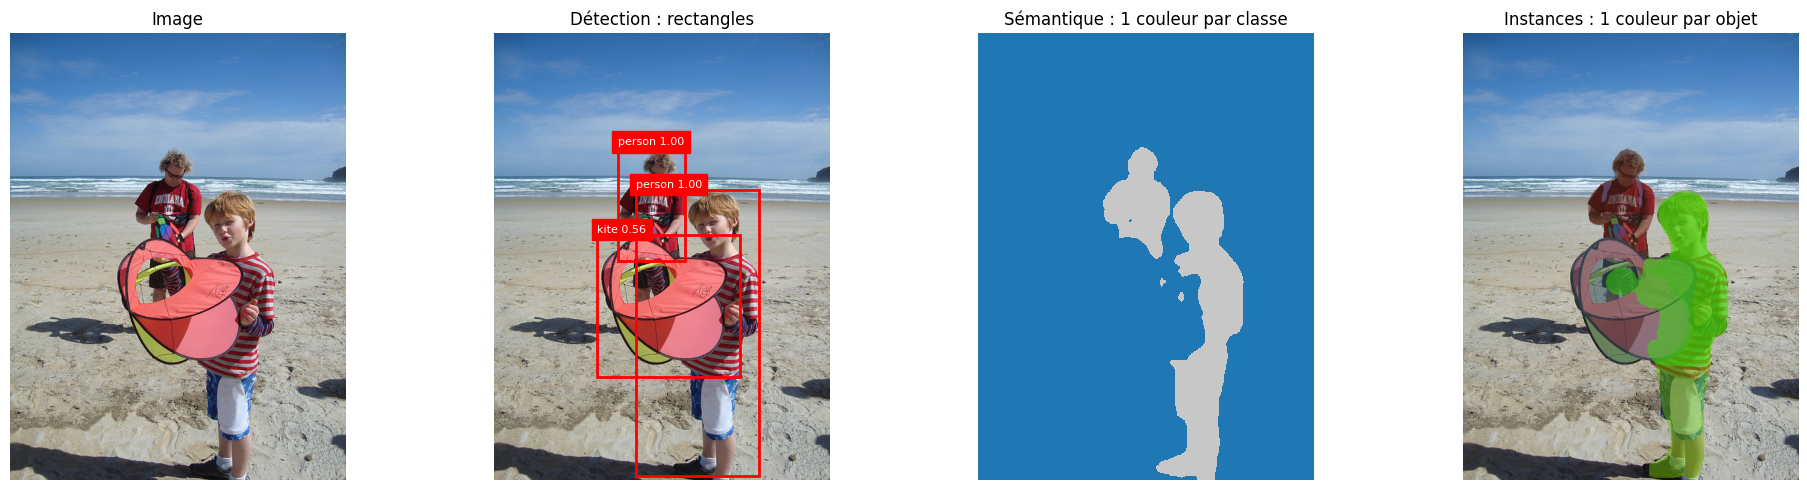

In [ ]:
i = selected[1]; img = images[i]
pd_, pi_ = det_preds[i], inst_preds[i]
kd, ki = pd_['scores'] >= 0.5, pi_['scores'] >= 0.5
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img); axes[0].set_title('Image'); axes[0].axis('off')
draw_boxes(axes[1], img, pd_['boxes'][kd].numpy(), pd_['labels'][kd].numpy(), pd_['scores'][kd].numpy(), color='red', title='Détection : rectangles')
axes[2].imshow(sem_preds[i], cmap='tab20', vmin=0, vmax=20, interpolation='nearest'); axes[2].set_title('Sémantique : 1 couleur par classe'); axes[2].axis('off')
overlay(axes[3], img, pi_['masks'][ki], 'Instances : 1 couleur par objet')
plt.tight_layout(); plt.show()

In [ ]:
resume = pd.DataFrame([
    ['Object Detection', 'Faster R-CNN', 'Rectangles', f'mAP@50 = {map50:.3f} · mAP@50:95 = {map5095:.3f} · Precision = {precision:.0%} · Recall = {recall:.0%}'],
    ['Semantic Segmentation', 'DeepLabV3', 'Masque par classe', f'mIoU = {miou:.3f} · Dice = {mdice:.3f} · Pixel Accuracy = {pixel_acc:.0%}'],
    ['Instance Segmentation', 'Mask R-CNN', 'Masque par objet', f'Mask mAP@50 = {mask_map50:.3f} · Mask mAP@50:95 = {mask_map5095:.3f}'],
], columns=['Tâche', 'Modèle', 'Sortie', 'Résultats'])
display(resume)

,Tâche,Modèle,Sortie,Résultats
0,Object Detection,Faster R-CNN,Rectangles,mAP@50 = 0.636 · mAP@50:95 = 0.435 · Precision...
1,Semantic Segmentation,DeepLabV3,Masque par classe,mIoU = 0.504 · Dice = 0.569 · Pixel Accuracy =...
2,Instance Segmentation,Mask R-CNN,Masque par objet,Mask mAP@50 = 0.607 · Mask mAP@50:95 = 0.403


## Conclusion
- L'**IoU** est la base : elle mesure le chevauchement entre prédiction et Ground Truth.
- **Détection** : Precision, Recall et mAP. **Sémantique** : mIoU et Dice. **Instances** : Mask mAP.
- Une métrique globale élevée ne suffit pas : la Pixel Accuracy peut cacher de mauvais résultats sur les petites classes.
- Les valeurs obtenues viennent d'un petit échantillon (`N_IMAGES` images) : elles donnent une idée, pas un score officiel.

**Sources** : COCO Detection Evaluation (cocodataset.org) · Torchvision pre-trained models, DeepLabV3, Mask R-CNN (docs PyTorch) · torchmetrics.